# STATS 425 · Week 9 lab
**Embeddings and retrieval**  
**TA:** Ali Kaazempur-Mofrad

In Week 1, we used a language model's log-probabilities to score text. In Weeks 4–7, we trained small policies with rewards and preferences, and in Week 8, we measured a fixed model's uncertainty. Today, we turn to the **text-mining** side of the course: we represent documents as vectors, search for the documents closest to a question, group documents into topics without using their labels, and retrieve evidence to place in front of a question.

| Section | Question we answer |
|---|---|
| 1. Documents as vectors | How can we turn a document into a vector of numbers? |
| 2. Similarity search | Which documents are closest to a question, and how do we measure retrieval quality? |
| 3. Topics from similarity | Can we recover the topics without using their labels? |
| 4. Retrieval before answering | How do we place retrieved evidence in a prompt? |
| 5. Scoring answers with DistilGPT2 | Does retrieved evidence raise the probability of a correct answer? |


**Set up the notebook:** The code below imports the libraries and sets a random seed so the results are repeatable.

In [7]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sklearn
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import normalize

SEED = 425

print(f"Setup complete. scikit-learn {sklearn.__version__}")

Setup complete. scikit-learn 1.7.0


## 1 · Documents as vectors

So far, our models have taken token IDs or numbers as input. Many text-mining tasks start with a simpler question: **which documents are about the same thing?** To answer it with statistics, we first turn each document into a vector of numbers.

**Meet the corpus:** A collection of documents is called a **corpus**. Ours has 36 short documents, written for this lab, on four topics: kidney exchange, academic hiring, weather, and cooking. Each document has an ID (`K1`–`K9`, `J1`–`J9`, `W1`–`W9`, `C1`–`C9`) and a topic label. We use the labels only to check our results; none of the methods in Sections 1–3 sees them.

The code below stores the corpus and prints one example per topic.

In [8]:
TOPICS = ("kidney exchange", "academic hiring", "weather", "cooking")

DOCUMENTS = [
    # (document ID, topic, text)
    ("K1", "kidney exchange",
     "A kidney exchange helps patients who have a willing living donor whose kidney is "
     "incompatible with them. Two incompatible patient-donor pairs can swap donors, so each "
     "patient receives a compatible kidney."),
    ("K2", "kidney exchange",
     "Whether a donor kidney is compatible with a patient depends on blood type and on "
     "antibodies in the patient's blood. A crossmatch test checks whether those antibodies "
     "would attack the donor kidney."),
    ("K3", "kidney exchange",
     "A patient with blood type O can usually receive a kidney only from a type O donor, so "
     "type O patients often wait longer for a compatible donor in a kidney exchange."),
    ("K4", "kidney exchange",
     "An altruistic donor gives a kidney without naming a patient. Such a donor can start a "
     "chain of kidney transplants, in which each patient's paired donor gives a kidney to the "
     "next patient in the chain."),
    ("K5", "kidney exchange",
     "In a two-way kidney swap, the four surgeries are usually scheduled on the same day, so no "
     "donor can back out after their own patient has received a kidney."),
    ("K6", "kidney exchange",
     "Larger kidney exchange pools find more transplants because each incompatible "
     "patient-donor pair has more potential partners. Many programs combine pairs from "
     "several transplant centers into one pool."),
    ("K7", "kidney exchange",
     "Kidneys from deceased donors are offered to patients on a waiting list, which ranks "
     "patients using factors such as time spent waiting and how hard each patient is to "
     "match with a donor."),
    ("K8", "kidney exchange",
     "Fairness is a central question in kidney allocation. A policy that maximizes the total "
     "number of transplants can still leave hard-to-match patients waiting much longer than "
     "other patients."),
    ("K9", "kidney exchange",
     "Matching algorithms for kidney exchange search the pool of incompatible patient-donor "
     "pairs for cycles and chains. Limiting the length of each cycle keeps the number of "
     "transplant surgeries that must happen together manageable."),
    ("J1", "academic hiring",
     "Each fall, university departments advertise faculty positions. Applicants submit a "
     "cover letter, a curriculum vitae, research and teaching statements, and reference "
     "letters to each department."),
    ("J2", "academic hiring",
     "A hiring committee reads the faculty applications and builds a short list of applicants "
     "to interview. Because the committee has limited time, many qualified applicants never "
     "receive an interview."),
    ("J3", "academic hiring",
     "Faculty job interviews often begin with a short video call, followed by a campus visit "
     "for a few finalists. A campus visit usually includes a research talk and meetings with "
     "faculty and students in the department."),
    ("J4", "academic hiring",
     "Some academic job markets let applicants send a small number of preference signals to "
     "show special interest in a faculty position. A signal helps a hiring committee identify "
     "applicants who are likely to accept a job offer."),
    ("J5", "academic hiring",
     "Interview congestion arises when many applicants apply to the same faculty positions and "
     "hiring committees cannot tell which applicants are seriously interested. Signals can "
     "spread interviews more evenly across applicants."),
    ("J6", "academic hiring",
     "After the campus visits, the department faculty vote and the department makes a job "
     "offer to its top applicant. The applicant may negotiate salary, start date, and research "
     "funding before accepting the offer."),
    ("J7", "academic hiring",
     "Faculty job offers often come with a deadline. An applicant holding one offer while "
     "waiting to hear from other departments must decide whether to accept early."),
    ("J8", "academic hiring",
     "Postdoctoral positions give recent graduates time to build a research record before "
     "they apply for faculty jobs in academic departments."),
    ("J9", "academic hiring",
     "A tenure-track assistant professor is reviewed for tenure by the department after "
     "several years, based on research, teaching, and service to the university."),
    ("W1", "weather",
     "Weather describes short-term conditions of the air, such as temperature, humidity, wind, "
     "and rain. Climate describes average weather conditions over many years."),
    ("W2", "weather",
     "Clouds form when rising air cools and water vapor in the air condenses into tiny "
     "droplets. The temperature at which water vapor begins to condense is called the dew "
     "point."),
    ("W3", "weather",
     "Relative humidity compares the water vapor in the air with the most water vapor the air "
     "could hold at its temperature. Warm air can hold more water vapor than cold air."),
    ("W4", "weather",
     "A cold front forms where cold air pushes under warm air. The warm air is forced upward, "
     "and the weather along the front often turns to showers or thunderstorms."),
    ("W5", "weather",
     "Air pressure is the weight of the air above a place. Falling air pressure often signals "
     "that stormy weather is approaching, while rising air pressure usually brings clear "
     "weather."),
    ("W6", "weather",
     "Weather forecasters run computer models of the air many times from slightly different "
     "starting conditions. The spread of these runs shows how uncertain the weather forecast "
     "is."),
    ("W7", "weather",
     "A weather forecast of a 30 percent chance of rain means that, over many days with the "
     "same forecast, rain should fall on about three days in ten."),
    ("W8", "weather",
     "Coastal towns often have milder weather than inland towns because the ocean warms and "
     "cools more slowly than land, which keeps the air temperature steadier."),
    ("W9", "weather",
     "Thunderstorms need moist air, unstable air, and something that lifts the air, such as a "
     "cold front or an area of low air pressure."),
    ("C1", "cooking",
     "Searing meat in a very hot pan browns its surface through the Maillard reaction, a set "
     "of reactions between amino acids and sugars that gives cooked food new flavors."),
    ("C2", "cooking",
     "Bread dough rises because yeast in the dough ferments sugars and releases carbon "
     "dioxide gas, which is trapped by a network of gluten proteins."),
    ("C3", "cooking",
     "Kneading bread dough develops gluten, which makes the dough stretchy and helps the "
     "bread hold its shape as it rises and bakes."),
    ("C4", "cooking",
     "Salt does more than add flavor to food: in bread dough it strengthens gluten, and on "
     "vegetables it draws out moisture before cooking."),
    ("C5", "cooking",
     "At high altitude, water boils at a lower temperature because of the lower air pressure, "
     "so pasta and beans take longer to cook in the mountains."),
    ("C6", "cooking",
     "Braising cooks tough cuts of meat slowly in a little liquid in a covered pot, which "
     "turns connective tissue into gelatin and makes the meat tender."),
    ("C7", "cooking",
     "Baking soda releases carbon dioxide when it reacts with an acid such as buttermilk or "
     "lemon juice, which makes pancakes and quick bread rise as they cook."),
    ("C8", "cooking",
     "Recipes written for sea level often need changes for cooking and baking in the "
     "mountains, where cakes can rise too fast and liquids evaporate faster."),
    ("C9", "cooking",
     "Mayonnaise is an emulsion: egg yolk helps tiny droplets of oil stay mixed with lemon "
     "juice or vinegar instead of separating, so no cooking is needed."),
]

doc_ids = [doc_id for doc_id, _, _ in DOCUMENTS]
doc_topics = [topic for _, topic, _ in DOCUMENTS]
doc_texts = [text for _, _, text in DOCUMENTS]
TEXT_BY_ID = dict(zip(doc_ids, doc_texts))

print(f"Documents: {len(DOCUMENTS)} | Topics: {len(TOPICS)}")
print(f"{'Topic':<18}{'Documents':>10}   Example")
print("-" * 92)
for topic in TOPICS:
    members = [i for i, t in enumerate(doc_topics) if t == topic]
    first = members[0]
    print(f"{topic:<18}{len(members):>10}   {doc_ids[first]}: {doc_texts[first][:56]}...")

Documents: 36 | Topics: 4
Topic              Documents   Example
--------------------------------------------------------------------------------------------
kidney exchange            9   K1: A kidney exchange helps patients who have a willing livi...
academic hiring            9   J1: Each fall, university departments advertise faculty posi...
weather                    9   W1: Weather describes short-term conditions of the air, such...
cooking                    9   C1: Searing meat in a very hot pan browns its surface throug...


### Weighted word counts

**Count the words:** The simplest vector is a **bag of words**: one entry per word in the vocabulary, holding the number of times the word appears in the document. Word order is ignored. Very common words such as "the" and "of" say little about the topic, so we drop a standard list of English **stop words**.

**Weight the counts:** A word that appears in many documents, such as `kidney`, which appears in most of our kidney documents, helps less to tell documents apart than a word that appears in only one or two. **Term frequency–inverse document frequency (TF-IDF)** multiplies each count by a weight that is larger for rarer words. For a term $t$ and a document $d$ in a corpus of $n$ documents:

- $\mathrm{tf}(t,d)$ is the number of times $t$ appears in $d$ (the term frequency);
- $\mathrm{df}(t)$ is the number of documents that contain $t$ (the document frequency);
- scikit-learn's default inverse document frequency is

$$
\mathrm{idf}(t)=\log\left(\frac{1+n}{1+\mathrm{df}(t)}\right)+1
$$

Let $v_d$ denote the vector with entries $v_{d,t}=\mathrm{tf}(t,d)\,\mathrm{idf}(t)$, one for each term $t$ in the vocabulary. The **final weights** of document $d$ are the entries of $v_d/\lVert v_d\rVert$, where $\lVert v_d\rVert$ is the Euclidean length of $v_d$, so every document vector has length 1. Without this division, long documents would get larger vectors simply because they contain more words.

<details><summary>Why the "+1" terms?</summary>

---

Adding 1 inside the fraction acts as if one extra document contained every term once, which prevents division by zero. Adding 1 outside the logarithm keeps a term that appears in every document from receiving weight zero: its idf is $\log\left(\frac{1+n}{1+n}\right)+1=1$.

---

</details>

**Build the TF-IDF vectors:** `TfidfVectorizer` learns the vocabulary and the idf weights from our 36 documents and returns a matrix $X$ with one row per document and one column per term. For each term in document `K4`, the code then prints its count $\mathrm{tf}(t,d)$, its document frequency $\mathrm{df}(t)$, its idf, the product $v_{d,t}$, and its final weight.


In [9]:
vectorizer = TfidfVectorizer(stop_words="english")
X = vectorizer.fit_transform(doc_texts)          # sparse matrix: documents x terms
vocabulary = vectorizer.get_feature_names_out()

# Raw counts with the same vocabulary, to check the TF-IDF formula.
counts = CountVectorizer(vocabulary=vectorizer.vocabulary_).fit_transform(doc_texts).toarray()
n_docs = counts.shape[0]
doc_freq = (counts > 0).sum(axis=0)
idf = np.log((1 + n_docs) / (1 + doc_freq)) + 1

row = doc_ids.index("K4")
raw_weights = counts[row] * idf
unit_weights = raw_weights / np.linalg.norm(raw_weights)
assert np.allclose(unit_weights, X[row].toarray()[0])   # same as scikit-learn's row for K4

print(f"X has {X.shape[0]} rows (documents) and {X.shape[1]} columns (terms).")
print(f"Nonzero entries: {X.nnz} of {X.shape[0] * X.shape[1]} ({X.nnz / (X.shape[0] * X.shape[1]):.1%}); "
      f"a document uses {X.nnz / X.shape[0]:.1f} of the {X.shape[1]} terms on average")
print()
print(f"K4: {TEXT_BY_ID['K4']}")
print("-" * 78)
print(f"{'Term':<14}{'Count':>7}{'Docs with term':>16}{'idf':>8}{'Count x idf':>14}{'Final weight':>15}")
for j in np.argsort(-unit_weights)[:10]:
    print(f"{vocabulary[j]:<14}{counts[row, j]:>7d}{doc_freq[j]:>16d}{idf[j]:>8.3f}"
          f"{raw_weights[j]:>14.3f}{unit_weights[j]:>15.3f}")
print("-" * 78)
print(f"Terms with a nonzero weight in K4: {np.count_nonzero(unit_weights)}")
print(f"Sum of squared final weights: {np.sum(unit_weights ** 2):.4f}")

X has 36 rows (documents) and 344 columns (terms).
Nonzero entries: 515 of 12384 (4.2%); a document uses 14.3 of the 344 terms on average

K4: An altruistic donor gives a kidney without naming a patient. Such a donor can start a chain of kidney transplants, in which each patient's paired donor gives a kidney to the next patient in the chain.
------------------------------------------------------------------------------
Term            Count  Docs with term     idf   Count x idf   Final weight
chain               2               1   3.918         7.836          0.427
kidney              3               8   2.414         7.241          0.395
donor               3               8   2.414         7.241          0.395
patient             3               8   2.414         7.241          0.395
gives               2               2   3.512         7.025          0.383
naming              1               1   3.918         3.918          0.213
paired              1               1   3.918       

Most entries of $X$ are zero: each short document uses only about 14 of the corpus's 344 terms. The table shows the 10 terms in `K4`. Its final weights equal the entries of its row in $X$, the matrix the rest of the lab uses.

`altruistic` appears in only one document, so it has the largest possible idf. `kidney` appears in eight documents and has a smaller idf, but it appears three times in `K4`, so its product $\mathrm{tf}\times\mathrm{idf}$, and therefore its final weight, is larger than that of `altruistic`. `chain` combines both effects: it appears twice in `K4` and in no other document, so it receives the largest final weight. TF-IDF rewards words that are frequent **in this document** and rare **in the corpus**.

The term `chain` is counted in only one document even though `K9` mentions "chains", and `kidney` is counted in only eight documents even though all nine kidney documents mention kidneys (`K7` says "Kidneys"). The vectorizer treats different word forms as different terms.


### Cosine similarity

Two documents about the same topic should share heavily weighted terms. For vectors $a$ and $b$, the **cosine similarity** is

$$
\cos(a,b)=\frac{a^\top b}{\lVert a\rVert\,\lVert b\rVert}
$$

TF-IDF weights are never negative, so the cosine lies between 0 (no shared terms) and 1 (the same direction). Each row of $X$ has length 1, so the denominator is 1 and the cosine similarity of two documents is the dot product of their rows. Entry $(i,j)$ of $XX^\top$ is the dot product of rows $i$ and $j$, so $XX^\top$ contains the cosine similarity of every pair of documents.

**Compare four documents:** The code below prints the cosine similarities among two kidney documents (`K4`, `K9`), one weather document (`W5`), and one cooking document (`C5`), and lists the terms each pair shares.


In [10]:
similarity = (X @ X.T).toarray()   # rows have length 1, so dot products are cosines


def shared_terms(u, v, limit=4):
    # Terms with nonzero weight in both sparse rows, ordered by the product of their weights.
    weights_u = dict(zip(u.indices, u.data))
    weights_v = dict(zip(v.indices, v.data))
    common = sorted(set(weights_u) & set(weights_v), key=lambda j: -weights_u[j] * weights_v[j])
    return [vocabulary[j] for j in common[:limit]]


chosen = ["K4", "K9", "W5", "C5"]
rows = [doc_ids.index(d) for d in chosen]
print("COSINE SIMILARITY")
print(f"{'':6}" + "".join(f"{d:>8}" for d in chosen))
for d, i in zip(chosen, rows):
    print(f"{d:<6}" + "".join(f"{similarity[i, j]:>8.3f}" for j in rows))

print("\nSHARED TERMS")
for a, b in [("K4", "K9"), ("W5", "C5"), ("K4", "W5")]:
    terms = shared_terms(X[doc_ids.index(a)], X[doc_ids.index(b)])
    print(f"{a}-{b}: {', '.join(terms) if terms else '(none)'}")

COSINE SIMILARITY
            K4      K9      W5      C5
K4       1.000   0.177   0.000   0.000
K9       0.177   1.000   0.000   0.000
W5       0.000   0.000   1.000   0.196
C5       0.000   0.000   0.196   1.000

SHARED TERMS
K4-K9: kidney, patient, donor
W5-C5: pressure, air
K4-W5: (none)


The two kidney documents share three weighted terms, so their cosine is above zero. `W5` (weather) and `C5` (cooking) belong to different topics, but both mention air pressure, and their cosine is even slightly higher than that of the two kidney documents. `K4` and `W5` share no terms, so their cosine is exactly 0. A bag-of-words similarity measures **word overlap**, not meaning: it can link different topics that share words, and it misses documents that discuss the same idea in different words.

## 2 · Similarity search

Section 1 compared documents with each other. **Search** compares a new piece of text, the **query**, with every document and returns the closest ones.

**Turn a query into a vector:** We transform the query with the same fitted vectorizer: the same vocabulary and the same idf weights learned from the corpus. A query word outside the vocabulary has no column, so it is **ignored**. We then rank the documents by cosine similarity with the query vector.

**Measure retrieval quality with precision@k:** A search returns a ranked list, and a reader usually looks only at the first few documents. **Precision@k** (P@k) measures how useful those first $k$ documents are: it is the **fraction of the top $k$ documents that are relevant** to the query. For example, if two of the top three documents are relevant, P@3 $=2/3$. P@1 asks only whether the top-ranked document is relevant.

Let $\mathcal{R}(x)$ denote the set of documents relevant to a query $x$, and let $d_{(1)},d_{(2)},\ldots$ denote the documents ranked from most to least similar to $x$. Then

$$
\text{P@}k(x)=\frac{1}{k}\sum_{j=1}^{k}\mathbf{1}\{d_{(j)}\in\mathcal{R}(x)\}
$$

The sum counts the relevant documents among the top $k$, and dividing by $k$ turns the count into a fraction.

**Rank the documents for one question:** To measure precision, we wrote eight test questions, $x_1,\ldots,x_8$ (`Q1`–`Q8`, two per topic), and for each one we chose the three documents in the corpus that best answer it as its **relevant documents**. The search itself never sees these labels. The code below defines the questions and their relevant documents, then shows the five highest-ranked documents for `Q5` with their cosine similarity, whether they are labeled relevant, and the terms they share with the question.

In [11]:
QUESTIONS = [
    # (question ID, question, documents labeled relevant)
    ("Q1", "How can two incompatible patient-donor pairs both receive a kidney?", {"K1", "K5", "K9"}),
    ("Q2", "What kind of donor can start a chain of kidney transplants?", {"K4", "K9", "K1"}),
    ("Q3", "Why do many qualified applicants for faculty positions never get an interview?", {"J2", "J5", "J4"}),
    ("Q4", "What happens during a campus visit for a faculty job?", {"J3", "J6", "J2"}),
    ("Q5", "What is the temperature at which water vapor starts to condense called?", {"W2", "W3", "W1"}),
    ("Q6", "What does falling air pressure usually signal?", {"W5", "W4", "W9"}),
    ("Q7", "Why does bread dough rise?", {"C2", "C3", "C7"}),
    ("Q8", "Why do noodles need extra time at a high elevation?", {"C5", "C8", "W5"}),
]
question_ids = [qid for qid, _, _ in QUESTIONS]
question_texts = [question for _, question, _ in QUESTIONS]

Q = vectorizer.transform(question_texts)      # one row per question, same columns as X
tfidf_scores = (Q @ X.T).toarray()            # cosine similarity: questions x documents


def ranking(scores):
    # Document indices from most to least similar; ties keep the corpus order.
    return np.argsort(-scores, kind="stable")


example = question_ids.index("Q5")
_, question, relevant = QUESTIONS[example]
print(f"Q5: {question}")
print("-" * 78)
print(f"{'Rank':<6}{'Doc':<6}{'Topic':<18}{'Cosine':>8}{'Relevant':>10}   Shared terms")
for rank, j in enumerate(ranking(tfidf_scores[example])[:5], start=1):
    mark = "yes" if doc_ids[j] in relevant else "no"
    terms = ", ".join(shared_terms(Q[example], X[j]))
    print(f"{rank:<6}{doc_ids[j]:<6}{doc_topics[j]:<18}{tfidf_scores[example, j]:>8.3f}{mark:>10}   {terms}")

Q5: What is the temperature at which water vapor starts to condense called?
------------------------------------------------------------------------------
Rank  Doc   Topic               Cosine  Relevant   Shared terms
1     W2    weather              0.628       yes   vapor, water, called, condense
2     W3    weather              0.478       yes   vapor, water, temperature
3     C5    cooking              0.163        no   water, temperature
4     W8    weather              0.067        no   temperature
5     W1    weather              0.063       yes   temperature


The two highest-ranked documents are the dew-point and humidity documents, which share several distinctive terms with the question. The third is the cooking document `C5`, which shares common terms such as `water` and `temperature` but is about a different topic. Its cosine is much lower than those of the two weather documents above it, but word overlap alone placed it ahead of the remaining relevant document, `W1`.

**Evaluate all eight questions:** With three relevant documents per question, P@1 and P@3 can both reach 1. For comparison, a random ranking of our 36 documents has expected precision $3/36\approx0.083$ for every $k$. The code below computes P@1 and P@3 for each question from the matrix of similarity scores and prints them with the top three documents (an asterisk marks a relevant one), and the question words that are not in the corpus vocabulary and therefore have no effect.

In [12]:
def precision_at_k(scores, k):
    # For each question: the fraction of its top-k documents that are labeled relevant.
    values = []
    for row, (_, _, relevant) in zip(scores, QUESTIONS):
        top = ranking(row)[:k]
        values.append(np.mean([doc_ids[j] in relevant for j in top]))
    return np.array(values)


analyzer = vectorizer.build_analyzer()     # the same lowercasing, tokenizing, and stop-word removal
p_at_1 = precision_at_k(tfidf_scores, 1)
p_at_3 = precision_at_k(tfidf_scores, 3)

print(f"{'Question':<10}{'P@1':>6}{'P@3':>7}   {'Top 3 (* = relevant)':<24}{'Ignored question words'}")
print("-" * 82)
for i, (qid, question, relevant) in enumerate(QUESTIONS):
    top = [doc_ids[j] + ("*" if doc_ids[j] in relevant else "") for j in ranking(tfidf_scores[i])[:3]]
    ignored = [word for word in analyzer(question) if word not in vectorizer.vocabulary_]
    print(f"{qid:<10}{p_at_1[i]:>6.2f}{p_at_3[i]:>7.2f}   {', '.join(top):<24}{', '.join(ignored) or '-'}")
print("-" * 82)
print(f"{'Mean':<10}{p_at_1.mean():>6.3f}{p_at_3.mean():>7.3f}")
print(f"{'Random':<10}{3 / 36:>6.3f}{3 / 36:>7.3f}   (expected precision of a random ranking)")

Question     P@1    P@3   Top 3 (* = relevant)    Ignored question words
----------------------------------------------------------------------------------
Q1          1.00   0.33   K1*, K4, K6             -
Q2          1.00   0.67   K4*, K1*, K6            kind
Q3          1.00   0.67   J2*, J5*, J1            -
Q4          1.00   0.67   J3*, J6*, J4            happens
Q5          1.00   0.67   W2*, W3*, C5            starts
Q6          1.00   0.67   W5*, W9*, C4            -
Q7          1.00   0.67   C3*, C4, C2*            -
Q8          1.00   0.67   C5*, W9, C8*            noodles, extra, elevation
----------------------------------------------------------------------------------
Mean       1.000  0.625
Random     0.083  0.083   (expected precision of a random ranking)


For every question, the top-ranked document is relevant, and the mean P@3 is far above the random-ranking value of about 0.083. Most misses at ranks 2–3 are documents from the right topic that we did not label relevant (for example, `K4` and `K6` for `Q1`). A few come from another topic through a single shared word: `C4` ranks third for `Q6` only because both contain `does`.

`Q8` is the hardest case. Its key words, `noodles` and `elevation`, are not in the vocabulary, so only `need`, `time`, and `high` count. The relevant documents say `pasta`, `altitude`, and `mountains` instead. `C5` ranks first only because it shares the word `high`, and the weather document `W9` ranks second because it shares `need`. TF-IDF treats synonyms and different word forms as unrelated columns.

TF-IDF could match `Q8` to `C5` better if words were reduced to a common stem, if synonyms were added, or if the vectors placed related words close to each other.


## 3 · Topics from similarity

Search starts from a query. We can also ask a question about the whole corpus: **do the documents form groups?** If documents on the same topic share words, the matrix of cosine similarities $XX^\top$ should show it.

To see all pairwise similarities at once, the code below draws $XX^\top$ as a heat map, with the documents ordered by topic. The diagonal (each document compared with itself, cosine 1) is left blank so that the other values are easier to see. The code also prints the average cosine for pairs of documents within the same topic and for pairs from different topics.


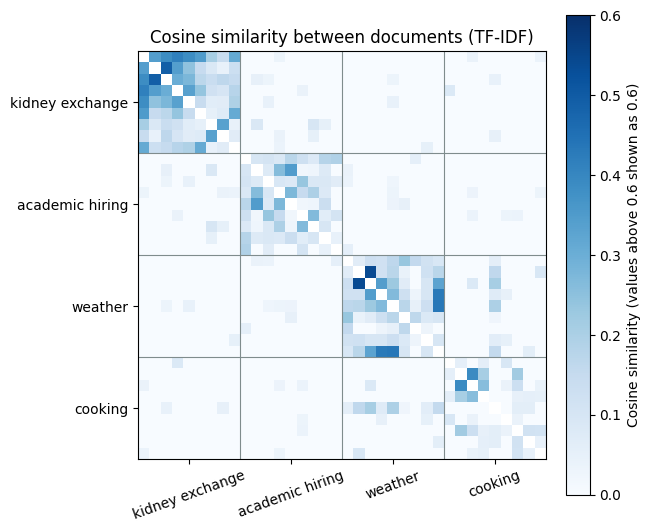

Average cosine, same topic:       0.132
Average cosine, different topics: 0.006


In [13]:
topic_index = np.array([TOPICS.index(t) for t in doc_topics])
same_topic = topic_index[:, None] == topic_index[None, :]
off_diagonal = ~np.eye(len(doc_ids), dtype=bool)
within = similarity[same_topic & off_diagonal].mean()
between = similarity[~same_topic].mean()

shown = similarity.copy()
np.fill_diagonal(shown, np.nan)
cmap = plt.get_cmap("Blues").copy()
cmap.set_bad("white")

fig, ax = plt.subplots(figsize=(6.4, 5.4), constrained_layout=True)
image = ax.imshow(shown, cmap=cmap, vmin=0, vmax=0.6)
for boundary in (8.5, 17.5, 26.5):
    ax.axhline(boundary, color="#7F8C8D", linewidth=0.8)
    ax.axvline(boundary, color="#7F8C8D", linewidth=0.8)
centers = [4, 13, 22, 31]
ax.set_xticks(centers, TOPICS, rotation=20)
ax.set_yticks(centers, TOPICS)
ax.set_title("Cosine similarity between documents (TF-IDF)")
fig.colorbar(image, ax=ax, label="Cosine similarity (values above 0.6 shown as 0.6)")
plt.show()

print(f"Average cosine, same topic:       {within:.3f}")
print(f"Average cosine, different topics: {between:.3f}")

If documents on the same topic share vocabulary, the four squares along the diagonal should be darker than the rest of the map, and they are. The cooking block is the lightest, because the cooking documents cover different dishes (bread, meat, sauces) and share fewer words. Most entries outside the blocks are close to zero, but not all: a few weather–cooking pairs, such as `W5` and `C5`, share words. The average cosine within a topic is many times the average between topics, yet it is still small, because short documents share only a few words even when they discuss the same topic.


### Latent semantic analysis

Our vectors have $M=344$ entries, one per term, and most of them are zero. But terms on the same topic tend to appear in the same documents: `donor`, `patient`, and `kidney` usually occur together. **Latent semantic analysis (LSA)** replaces the $M$ term weights with a few new coordinates, one per **direction**. A direction is a weighted combination of terms that tend to occur together, and a document's coordinate on it is large when the document uses those terms.

LSA finds the directions with the **singular value decomposition (SVD)**. Any $n\times M$ matrix can be written as $X=U\Sigma V^\top$, where $\Sigma$ is a diagonal matrix of **singular values** in decreasing order. LSA keeps only the $r$ largest:

$$
X\approx U_r\,\Sigma_r\,V_r^\top
$$

- **Directions:** The $r$ columns of the $M\times r$ matrix $V_r$ are the directions. Each column has one entry per term, called the term's **loading**. A term with a large positive or negative loading is important for that direction.
- **Strength:** $\Sigma_r$ is the $r\times r$ diagonal matrix of the $r$ largest singular values. A larger singular value means its direction accounts for more of $X$.
- **New coordinates:** The rows of the $n\times r$ matrix $U_r\Sigma_r=XV_r$ are the documents' new coordinates: $r$ numbers instead of $M$.

**Fit LSA with four directions:** The code below prints the five terms with the largest absolute loadings for each direction and plots the documents in the new coordinates, colored by their true topic. The sign of each direction is arbitrary: flipping it changes nothing about the fit.


Direction  Terms with the largest absolute loadings
------------------------------------------------------------------------------
1          kidney (+0.50), donor (+0.42), patient (+0.39), type (+0.20), incompatible (+0.18)
2          air (+0.68), water (+0.25), vapor (+0.24), weather (+0.23), pressure (+0.23)
3          applicants (+0.40), faculty (+0.33), job (+0.23), offer (+0.19), department (+0.19)
4          dough (+0.46), bread (+0.40), gluten (+0.27), rises (+0.20), releases (+0.17)


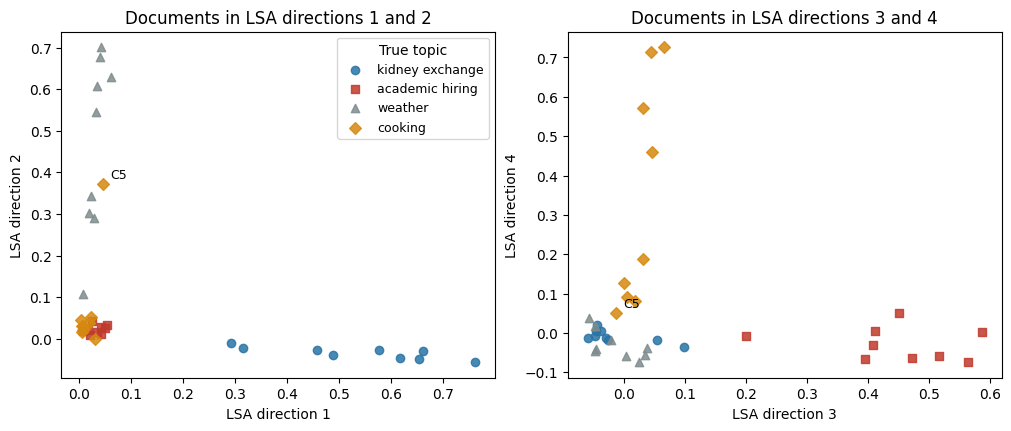

In [14]:
lsa = TruncatedSVD(n_components=4, random_state=SEED)
Z_lsa = lsa.fit_transform(X)          # document coordinates U_r Sigma_r, shape (36, 4)

print(f"{'Direction':<11}Terms with the largest absolute loadings")
print("-" * 78)
for c, loadings in enumerate(lsa.components_, start=1):
    top = np.argsort(-np.abs(loadings))[:5]
    print(f"{c:<11}" + ", ".join(f"{vocabulary[j]} ({loadings[j]:+.2f})" for j in top))

TOPIC_STYLE = {
    "kidney exchange": ("#2874A6", "o"),
    "academic hiring": ("#C0392B", "s"),
    "weather": ("#7F8C8D", "^"),
    "cooking": ("#D68910", "D"),
}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), constrained_layout=True)
for ax, (a, b) in zip(axes, [(0, 1), (2, 3)]):
    for topic, (color, marker) in TOPIC_STYLE.items():
        members = topic_index == TOPICS.index(topic)
        ax.scatter(Z_lsa[members, a], Z_lsa[members, b], color=color, marker=marker,
                   s=36, alpha=0.85, label=topic)
    c5 = doc_ids.index("C5")
    ax.annotate("C5", (Z_lsa[c5, a], Z_lsa[c5, b]), textcoords="offset points", xytext=(5, 4), fontsize=9)
    ax.set_xlabel(f"LSA direction {a + 1}")
    ax.set_ylabel(f"LSA direction {b + 1}")
    ax.set_title(f"Documents in LSA directions {a + 1} and {b + 1}")
axes[0].legend(title="True topic", fontsize=9)
plt.show()

Each direction is dominated by one topic's vocabulary: the printed terms show a kidney direction, a weather direction, an academic-hiring direction, and a cooking direction (the order is set by the singular values). No topic labels were used; the directions come only from which words occur together.

In the left panel, the kidney and weather documents lie far from the origin along their own directions, while the hiring and cooking documents overlap near the origin. The right panel separates those two topics: the hiring documents spread along direction 3, and about half of the cooking documents (the bread and leavening ones: `C2`, `C3`, `C4`, `C7`) spread along direction 4, while the other cooking documents stay close to the origin. Two directions are not enough to separate four topics here. The cooking document `C5`, which talks about water, temperature, and air pressure, sits among the weather documents in the left panel.

### Clustering with k-means

**k-means** splits the documents into a chosen number of clusters and tries to minimize the total squared distance from each document to the mean (centroid) of its cluster. It alternates two steps: assign each document to the nearest centroid, then recompute each centroid. Each start reaches a local minimum, which depends on the starting centroids, so scikit-learn tries `n_init=10` starts and keeps the best one. (The "k" in the name counts clusters; it is not the $k$ of top-$k$ retrieval.)

Before clustering, we rescale each document's LSA coordinates to length 1. For unit vectors, $\lVert a-b\rVert^2=2-2\cos(a,b)$, so small distances correspond to large cosines, just as in Sections 1–2.

**Compare clusters with the true topics:** k-means numbers its clusters arbitrarily, so we cannot just check whether a document's cluster number equals its topic number: cluster 2 need not correspond to topic 2. Instead, we compare **pairs** of documents. For each pair, the true topics either put the two documents together or apart, and so do the clusters; the two groupings agree on the pair if they make the same call. The **Rand index** is the fraction of pairs on which the groupings agree. The **adjusted Rand index (ARI)** rescales it so that a perfect match scores 1, whatever the cluster numbers, and random clusters score about 0.

We cluster twice into 4 clusters: once using the four LSA coordinates and once using the full TF-IDF vectors. The code below runs both versions.


In [15]:
N_COMPONENTS = 4     # LSA directions used for clustering
N_CLUSTERS = 4

Z = TruncatedSVD(n_components=N_COMPONENTS, random_state=SEED).fit_transform(X)
Z_unit = normalize(Z)   # each row has length 1
labels_lsa = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED).fit_predict(Z_unit)
labels_raw = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED).fit_predict(X)


def print_confusion(labels, title):
    print(title)
    print(f"{'True topic':<18}" + "".join(f"{'Cluster ' + str(c):>11}" for c in range(N_CLUSTERS)))
    for t, topic in enumerate(TOPICS):
        print(f"{topic:<18}" + "".join(f"{np.sum((topic_index == t) & (labels == c)):>11d}"
                                       for c in range(N_CLUSTERS)))


print_confusion(labels_lsa, f"K-MEANS ON {N_COMPONENTS} LSA COORDINATES")
print(f"Adjusted Rand index: {adjusted_rand_score(topic_index, labels_lsa):.3f}\n")
print_confusion(labels_raw, "K-MEANS ON FULL TF-IDF VECTORS")
print(f"Adjusted Rand index: {adjusted_rand_score(topic_index, labels_raw):.3f}")

print("\nLSA clusters: documents in a cluster dominated by another topic")
for c in range(N_CLUSTERS):
    members = np.flatnonzero(labels_lsa == c)
    majority = np.bincount(topic_index[members], minlength=len(TOPICS)).argmax()
    for i in members:
        if topic_index[i] != majority:
            print(f"  {doc_ids[i]} ({doc_topics[i]}) is in the {TOPICS[majority]} cluster: {doc_texts[i][:50]}...")

ari = {"LSA": [], "Full TF-IDF": []}
for seed in range(10):
    ari["LSA"].append(adjusted_rand_score(
        topic_index, KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=seed).fit_predict(Z_unit)))
    ari["Full TF-IDF"].append(adjusted_rand_score(
        topic_index, KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=seed).fit_predict(X)))
print(f"\n{'ARI over seeds 0-9':<20}{'Min':>8}{'Mean':>8}{'Max':>8}")
for name, values in ari.items():
    print(f"{name:<20}{min(values):>8.3f}{np.mean(values):>8.3f}{max(values):>8.3f}")

K-MEANS ON 4 LSA COORDINATES
True topic          Cluster 0  Cluster 1  Cluster 2  Cluster 3
kidney exchange             0          0          0          9
academic hiring             0          0          9          0
weather                     0          9          0          0
cooking                     8          1          0          0
Adjusted Rand index: 0.924

K-MEANS ON FULL TF-IDF VECTORS
True topic          Cluster 0  Cluster 1  Cluster 2  Cluster 3
kidney exchange             9          0          0          0
academic hiring             0          0          5          4
weather                     0          8          1          0
cooking                     0          1          6          2
Adjusted Rand index: 0.538

LSA clusters: documents in a cluster dominated by another topic
  C5 (cooking) is in the weather cluster: At high altitude, water boils at a lower temperatu...

ARI over seeds 0-9       Min    Mean     Max
LSA                    0.924   0.924   0.924
Ful

Each table counts how many documents of each true topic land in each cluster. With the four LSA coordinates, each cluster matches one topic, and only one document is misplaced: `C5`, the cooking document about air pressure, joins the weather cluster. The ARI is 0.92.

With the full TF-IDF vectors, k-means does clearly worse: the hiring and cooking documents are spread over two clusters that mix both topics, and the ARI is 0.54. Because k-means depends on its random starts, the last lines rerun both versions with ten other seeds. The LSA result is the same every time, while the full-vector ARI ranges from 0.61 to 0.86, always below LSA's.

The difference comes from the distances. In the full space, most pairs of documents share no terms, so most distances are close to $\sqrt{2}$ (cosine near 0), and k-means has little structure to work with. LSA keeps only the few directions that carry the topic structure.


## 4 · Retrieval before answering

A language model answers from what its weights store and from the text in its prompt. **Retrieval-augmented generation (RAG)** adds to the prompt: before the model answers, a search retrieves the documents most similar to the question and places them in the prompt as **evidence**.

Sections 4 and 5 test whether evidence helps. In this section, we build the prompts and check what the evidence contains. In Section 5, we measure how the evidence changes the probability that a language model assigns to the correct answer.

**Build three prompts for each question:** For each of the eight questions from Section 2, we wrote a short correct answer $a$ (for example, "a research talk" for `Q4`). Let $D_k(x)$ denote the top $k=3$ documents that the search from Section 2 returns for question $x$. Each prompt ends with `Answer:`, where the answer would begin:

| Prompt | Contents |
|---|---|
| (a) Question only | the question $x$ |
| (b) Retrieved evidence | the documents $D_k(x)$, then the question $x$ |
| (c) Unrelated evidence | the 3 documents retrieved for a question on a **different topic**, then $x$ |

**Why prompt (c)?** Adding evidence changes two things at once: the prompt becomes longer, and it gains information. Prompt (c) is a **control** that changes only the first. It has the same format and the same number of documents as (b), but its evidence is about another topic; for example, `Q1` (kidney exchange) receives the documents retrieved for `Q5` (weather). If (b) helps and (c) does not, the help comes from what the evidence says.

The code below prints prompt (b) for `Q4`, followed by its answer. It then lists, for every question, the documents in prompts (b) and (c), how many of them are relevant, and whether they contain the answer's words.


In [16]:
ANSWERS = {
    # Short correct answers; each starts with a space because it follows "Answer:".
    "Q1": " swap donors",
    "Q2": " an altruistic donor",
    "Q3": " limited time",
    "Q4": " a research talk",
    "Q5": " the dew point",
    "Q6": " stormy weather",
    "Q7": " carbon dioxide",
    "Q8": " lower air pressure",
}
K_EVIDENCE = 3


def retrieve(question, k=K_EVIDENCE):
    scores = (vectorizer.transform([question]) @ X.T).toarray()[0]
    return [doc_ids[j] for j in ranking(scores)[:k]]


def build_prompt(question, evidence_ids=()):
    lines = []
    if evidence_ids:
        lines.append("Evidence:")
        lines += [f"- {TEXT_BY_ID[d]}" for d in evidence_ids]
    lines += [f"Question: {question}", "Answer:"]
    return "\n".join(lines)


retrieved = {qid: retrieve(question) for qid, question, _ in QUESTIONS}
# Control: the evidence retrieved for the question four places later, which is about a different topic.
unrelated = {qid: retrieved[question_ids[(i + 4) % len(QUESTIONS)]] for i, qid in enumerate(question_ids)}


def contains_answer(evidence_ids, answer):
    return answer.strip().lower() in " ".join(TEXT_BY_ID[d] for d in evidence_ids).lower()


print("PROMPT (b) FOR Q4")
print("-" * 78)
print(build_prompt(QUESTIONS[3][1], retrieved["Q4"]) + ANSWERS["Q4"])
print("-" * 78)
print("(The model is scored on the answer tokens after 'Answer:'.)\n")

print(f"{'':<10}{'RETRIEVED EVIDENCE':<38}{'UNRELATED EVIDENCE'}")
print(f"{'Question':<10}{'Documents':<14}{'Relevant':>9}{'Has answer':>12}{'':<3}"
      f"{'Documents':<14}{'Relevant':>9}{'Has answer':>12}")
print("-" * 83)
for qid, question, relevant in QUESTIONS:
    columns = []
    for evidence in (retrieved[qid], unrelated[qid]):
        n_relevant = sum(d in relevant for d in evidence)
        found = "yes" if contains_answer(evidence, ANSWERS[qid]) else "no"
        columns.append(f"{', '.join(evidence):<14}{n_relevant:>7}/3{found:>12}")
    print(f"{qid:<10}{columns[0]}{'':<3}{columns[1]}")

PROMPT (b) FOR Q4
------------------------------------------------------------------------------
Evidence:
- Faculty job interviews often begin with a short video call, followed by a campus visit for a few finalists. A campus visit usually includes a research talk and meetings with faculty and students in the department.
- After the campus visits, the department faculty vote and the department makes a job offer to its top applicant. The applicant may negotiate salary, start date, and research funding before accepting the offer.
- Some academic job markets let applicants send a small number of preference signals to show special interest in a faculty position. A signal helps a hiring committee identify applicants who are likely to accept a job offer.
Question: What happens during a campus visit for a faculty job?
Answer: a research talk
------------------------------------------------------------------------------
(The model is scored on the answer tokens after 'Answer:'.)

          RET

Retrieval succeeded for every question: the retrieved evidence includes at least one relevant document and contains the answer's words, so a model that reads its prompt has the information it needs. The unrelated evidence contains no relevant document and never contains the answer. Evidence can only help if retrieval finds it: had the search missed the answer, prompt (b) would be no better than prompt (c).

In Section 5, we measure whether the evidence actually changes a language model's predictions.


## 5 · Scoring answers with DistilGPT2

We now bring in a language model, the pretrained **DistilGPT2**, and ask whether retrieved evidence helps it: how much does the evidence from Section 4 raise the probability that the model assigns to the correct answer?


In [17]:
import importlib.util, subprocess, sys
packages = ["transformers==4.57.6", "huggingface-hub==0.36.2", "tokenizers==0.22.2"]
if importlib.util.find_spec("torch") is None:
    packages.append("torch==2.8.0")
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *packages])
print("Setup complete.")

Setup complete.


In [18]:
import os, random, warnings
import torch
warnings.filterwarnings("ignore", message="IProgress not found")   # harmless progress-bar notice
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM

SEED = 425
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

MODEL_ID = "distilbert/distilgpt2"
REVISION = "2290a62682d06624634c1f46a6ad5be0f47f38aa"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=REVISION, use_safetensors=True
).to(device)
# GPT-2 has no dedicated PAD token. Mask padding by position, not by token ID.
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"
model.config.pad_token_id = tokenizer.pad_token_id
model.eval()
print("Device:", device, "| torch:", torch.__version__, "| transformers:", transformers.__version__)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Device: cpu | torch: 2.8.0 | transformers: 4.57.6
Parameters: 81,912,576


**Score the answer:** Instead of letting the model generate text, we measure how likely it finds the correct answer $a$ after each prompt from Section 4. If the answer has tokens $a_1,\ldots,a_T$, its log-probability is the sum of the log-probabilities of its tokens, each given the prompt and the answer tokens before it:

$$
\log p(a\mid \text{prompt})=\sum_{t=1}^{T}\log p(a_t\mid \text{prompt},a_{<t})
$$

**Evidence gain:** For question $x$, the **evidence gain** is how much the retrieved evidence raises this log-probability:

$$
\Delta(x)=\log p\big(a\mid D_k(x),x\big)-\log p(a\mid x)
$$

A gain of 0 means the evidence made no difference. A positive gain means the evidence made the correct answer more likely: it multiplied the answer's probability by $e^{\Delta}$. We compute the same gain for the unrelated evidence in prompt (c).

The code below first prints a token-by-token table for `Q4`, then the gains for all eight questions.

<details><summary>How the code scores the answer tokens</summary>

---

For each prompt, the code joins the prompt's token IDs and the answer's token IDs, runs the model once, and adds the log-probabilities of the answer tokens, each read from the position just before it.

Joining the token IDs gives the same tokens as tokenizing the joined text. GPT-2's tokenizer first splits text into pieces: each leading space stays attached to the word that follows it, and punctuation such as `:` forms a separate piece. Its merges never cross these pieces. Because each prompt ends with `Answer:` and each answer starts with a space, tokenizing the prompt and the answer separately gives the same tokens as tokenizing them together. The prompts are also well within DistilGPT2's limit of 1,024 tokens.

---

</details>


In [19]:
@torch.no_grad()
def answer_token_log_probs(prompt, answer):
    # Week 1's scoring: position t predicts token t + 1, so each answer token is scored by
    # the log-probabilities at the position just before it.
    prompt_ids = tokenizer.encode(prompt, add_special_tokens=False)
    answer_ids = tokenizer.encode(answer, add_special_tokens=False)
    ids = prompt_ids + answer_ids
    log_probs = model(input_ids=torch.tensor([ids], device=device)).logits[0, :-1].log_softmax(dim=-1)
    return [(tokenizer.decode([ids[position]]), log_probs[position - 1, ids[position]].item())
            for position in range(len(prompt_ids), len(ids))]


def answer_log_prob(prompt, answer):
    return sum(log_p for _, log_p in answer_token_log_probs(prompt, answer))


qid, question, _ = QUESTIONS[question_ids.index("Q4")]
print(f"{qid}: {question} | answer: {ANSWERS[qid]!r}")
print(f"{'Answer token':<14}{'p, question only':>18}{'p, with evidence':>18}")
alone = answer_token_log_probs(build_prompt(question), ANSWERS[qid])
with_evidence = answer_token_log_probs(build_prompt(question, retrieved[qid]), ANSWERS[qid])
for (token, log_p_alone), (_, log_p_evidence) in zip(alone, with_evidence):
    print(f"{token!r:<14}{math.exp(log_p_alone):>18.6f}{math.exp(log_p_evidence):>18.6f}")
print(f"{'Sum of log p':<14}{sum(v for _, v in alone):>18.3f}{sum(v for _, v in with_evidence):>18.3f}")

print("\n" + "=" * 86)
print(f"{'Question':<10}{'Answer':<22}{'(a) alone':>11}{'(b) retrieved':>15}{'(c) unrelated':>15}"
      f"{'Gain (b)':>10}{'Gain (c)':>10}")
print("-" * 86)
results = []
for qid, question, _ in QUESTIONS:
    answer = ANSWERS[qid]
    alone = answer_log_prob(build_prompt(question), answer)
    with_retrieved = answer_log_prob(build_prompt(question, retrieved[qid]), answer)
    with_unrelated = answer_log_prob(build_prompt(question, unrelated[qid]), answer)
    results.append((alone, with_retrieved, with_unrelated))
    print(f"{qid:<10}{answer!r:<22}{alone:>11.3f}{with_retrieved:>15.3f}{with_unrelated:>15.3f}"
          f"{with_retrieved - alone:>10.3f}{with_unrelated - alone:>10.3f}")
results = np.array(results)
gain_retrieved = results[:, 1] - results[:, 0]
gain_unrelated = results[:, 2] - results[:, 0]
print("-" * 86)
print(f"{'Mean':<32}{results[:, 0].mean():>11.3f}{results[:, 1].mean():>15.3f}{results[:, 2].mean():>15.3f}"
      f"{gain_retrieved.mean():>10.3f}{gain_unrelated.mean():>10.3f}")
print(f"\nRetrieved evidence raised log p(answer) for {np.sum(gain_retrieved > 0)} of {len(QUESTIONS)} questions.")
print(f"Unrelated evidence raised log p(answer) for {np.sum(gain_unrelated > 0)} of {len(QUESTIONS)} questions.")

Q4: What happens during a campus visit for a faculty job? | answer: ' a research talk'
Answer token    p, question only  p, with evidence


' a'                    0.000893          0.002417
' research'             0.001003          0.003596
' talk'                 0.000564          0.055045
Sum of log p             -21.406           -14.553

Question  Answer                  (a) alone  (b) retrieved  (c) unrelated  Gain (b)  Gain (c)
--------------------------------------------------------------------------------------
Q1        ' swap donors'            -23.938        -17.295        -24.543     6.643    -0.605
Q2        ' an altruistic donor'    -16.462         -7.663        -14.690     8.799     1.772


Q3        ' limited time'           -19.741        -14.424        -17.576     5.318     2.165
Q4        ' a research talk'        -21.406        -14.553        -20.601     6.853     0.805
Q5        ' the dew point'          -20.898         -9.250        -22.025    11.649    -1.127


Q6        ' stormy weather'         -19.998        -13.129        -23.551     6.869    -3.553
Q7        ' carbon dioxide'         -16.734        -14.013        -16.886     2.721    -0.152
Q8        ' lower air pressure'     -19.800        -15.044        -22.542     4.756    -2.742
--------------------------------------------------------------------------------------
Mean                                -19.872        -13.171        -20.302     6.701    -0.430

Retrieved evidence raised log p(answer) for 8 of 8 questions.
Unrelated evidence raised log p(answer) for 3 of 8 questions.


Retrieved evidence helps, and unrelated evidence does not. In the summary table, the retrieved evidence raised the log-probability of the correct answer for all eight questions. The mean gain is 6.70, which multiplies the answer's probability by about $e^{6.70}\approx800$; even the smallest gain (2.72, for `Q7`) multiplies it by about 15. The unrelated evidence has a mean gain of $-0.43$: on average, it made the correct answer slightly less likely. So the improvement comes from what the retrieved evidence says, not from the longer prompt.

The `Q4` table shows the gain token by token. The retrieved document `J3` says that a campus visit "usually includes a research talk". With this document in the prompt, every answer token becomes more likely, and ` talk` gains the most: its probability increases from 0.0006 to 0.055, about 100 times, which accounts for most of the gain of 6.85. Still, no token comes close to probability 1.

DistilGPT2 is a small model trained to continue text, not to answer questions. It likely gains by favoring words that appear in its prompt, not by understanding the question. That is still useful: retrieval puts the answer's words where the model can use them. With only eight questions, treat these numbers as an illustration, not as an estimate for other questions or models.


### How this maps to a language model

A language model answers from two sources: what its weights store, and the text in its prompt. Retrieval-augmented generation adds relevant text to the prompt, as in Sections 4 and 5: retrieve the documents most similar to the question, place them in the prompt as evidence, and let the model answer. In practice, the corpus can be very large, and the retriever is usually a learned model rather than TF-IDF. The original RAG system, for example, uses a dense retriever whose encoders were trained on question–passage pairs, so that a question lands near the passages that answer it. The pipeline is the same as ours.


## Recap

We followed a question from a corpus of documents to a scored answer:

**Documents → TF-IDF vectors → cosine similarity → retrieved evidence → evidence + question → answer log-probability**

TF-IDF turns each document into a vector that weights words frequent in the document and rare in the corpus. Cosine similarity ranks documents for a query, and precision@k measures how many of the top documents are relevant. The same similarities reveal topics: LSA compresses the vectors into a few directions, and k-means on those directions recovered our four topics almost exactly. Finally, retrieved documents become evidence in a prompt, and log-probabilities measure whether that evidence makes a correct answer more likely.

### Check your understanding

1. A word appears in all 36 documents. What is its idf under the formula we used, and why is it not zero?
2. A query contains only words that are not in the vocabulary. What is its TF-IDF vector, and what does the ranking look like?
3. Why do we compare the k-means clusters with the true topics using the adjusted Rand index instead of the fraction of documents whose cluster number equals their topic number?
4. Retrieved evidence raises an answer's log-probability by 2 nats. By what factor did the answer's probability change?
5. Why did we also score each answer after unrelated evidence?

<details><summary>Answers</summary>

---

1. With $n=36$ and $\mathrm{df}=36$, $\mathrm{idf}=\log(37/37)+1=1$, the smallest possible value. The "+1" outside the logarithm keeps the word from being dropped entirely; it still receives the lowest weight per occurrence.
2. Every entry is zero, so its dot product with every document is 0. All documents tie, and the ranking is arbitrary: the search has no information to use.
3. Cluster numbers are arbitrary labels; the same grouping could number its clusters in any order. The ARI compares which pairs of documents are grouped together, so it does not depend on the numbering, and it adjusts for agreement expected by chance.
4. It multiplied the probability by $e^{2}\approx7.4$, because $\log p_{\text{new}}-\log p_{\text{old}}=2$ means $p_{\text{new}}/p_{\text{old}}=e^{2}$.
5. Adding evidence also makes the prompt longer and changes its format. Unrelated evidence with the same number of documents and the same format is a control: an effect that appears with retrieved evidence but not with unrelated evidence can be attributed to the evidence's content.

---

</details>

### Next week: putting it all together

Next week, we review the whole sequence through one task, end to end. Starting from Week 6's noisy "Which number is largest?" task, we give a policy a supervised start, train it with rewards that score both its answers and its reported confidence, and finish by answering with a coverage guarantee. Each step reuses an idea from an earlier week in a few lines of code.

## References and further reading

- [scikit-learn: TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html): TF-IDF features, including the smoothed idf formula used here.
- [scikit-learn: TruncatedSVD](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html): latent semantic analysis.
- [Lewis et al. (2020): Retrieval-augmented generation for knowledge-intensive NLP tasks](https://arxiv.org/abs/2005.11401): retrieval before generation.
- [DistilGPT2 model card](https://huggingface.co/distilbert/distilgpt2): the pretrained model used in these labs.